# 1. Partición de los datos

Este proyecto busca que un modelo de visión artificial aprenda a reconocer diez tipos de geoformas redondeadas en imágenes satelitales, constituyendo la fase 2 de la metodología aplicada en mi trabajo de grado (TDG, Miguel Monterroza). La más importante es la clase aquí nombrada como **H2**, la cual es una depresión muy somera del terreno con contornos circulares a semicirculares (*sub-circular depression* o *SCD*, por sus síglas en inglés, nombre que recibe formalmente la geoforma en la literatura), que se asocia con filtraciones de hidrógeno natural desde el subsuelo hacia la superficie. Para saber si el modelo funciona hay que medirlo con imágenes que no vio al entrenarse, y cómo se separan esas imágenes es una de la decisiones más importantes del proyecto. Este notebook lo resuelve.

### Los datos

600 imágenes satélitales de la Map Static API de Google Maps, adquiridas con el pipeline del notebook de la fase 1 de la metodología del TDG; exactamente 60 por cada una de las 10 clases definidas en la siguiente tabla. La gran mayoría son heredadas del inventario "TableS1" de nueve clases publicado en Zenodo por Geymond et al. (2025) y utilizadas en el paper de Ginzburg et al. (2025), con algunos pocos reemplazos documentados en el TDG. Las 60 de la clase adicional (Jagüey) incorporada en este proyecto, son tomadas de un directorio (ArcGIS REST Services) de un proyecto preexistente (Lerma et al., 2025) y capturadas en la Alta Guajira, Colombia.
<br><small>*Nota. Así como los notebooks de la presente fase, el inventario (CSV Maestro) de las 600 imágenes y el notebook del pipeline de adquisición correspondiente, están dispuestos en el Zenodo del TDG. Para consultarlo, al igual que las referencias citadas anteriormente, remítase al documento principal del TDG.*</small>

| Clase | Qué es |
|---|---|
| H2 | SCD-H2: Depresión semicircular del terreno; la estructura de interés |
| Jagüey | Estanque excavado para acumular agua de lluvia, típico de La Guajira |
| Fairy circle | Manchas circulares sin vegetación rodeadas de pasto, en zonas áridas |
| Fairy fort | Recintos circulares antiguos de tierra, normalmente cubiertos de vegetación |
| Farm circle | Campos de cultivo circulares (riego por pivote) |
| Flooded dune | Lagunas entre dunas de arena |
| Impact crater | Cráteres de impacto de meteoritos |
| Karst | Depresiones formadas por disolución de la roca |
| Salt lake | Lagos salados |
| Thermokarst | Depresiones formadas al derretirse el suelo congelado |

Con las imágenes viene un CSV maestro con una fila por imagen: su número (`id`), su clase, la posición de su centro (`X_3857`, `Y_3857`) y el nivel de zoom con que se descargó (`zoom`). Las dos últimas se explican en la sección 1.3.

### ¿Por qué importa cómo se parten los datos?

Si las imágenes de evaluación se parecen demasiado a las de entrenamiento, el modelo parece bueno sin serlo, porque solo reconoce lo que ya vio. Es la **fuga de información**, y aquí el riesgo es real: varias imágenes pueden mostrar el mismo lugar de fondo o lugares vecinos casi idénticos, aunque se trate de estructuras distintas. Por eso las imágenes no se reparten al azar sino por **sitio real**, el conjunto de imágenes de un mismo lugar físico, que nunca se separan.

Con los sitios definidos se aparta un **holdout**, un conjunto de prueba final que no se toca hasta el notebook 4, y el conjunto de desarrollo del modelo se divide en **5 pliegues** para la **validación cruzada**: se entrena cinco veces, cada vez apartando un pliegue distinto para evaluar, de modo que el resultado no dependa de un reparto afortunado y se vea cuánto varía.

## 1.1 Configuración

Dos carpetas: `DATASET_DIR`, con las 10 subcarpetas de clase y el CSV maestro, y `OUT_DIR`, donde se guardan los resultados que leen los notebooks siguientes. En Colab, el proyecto vive en una carpeta de Google Drive que contiene `dataset/` (y, desde el notebook 1, `salidas/`). Su ubicación se indica en `CARPETA_DRIVE`; al ejecutar, Colab pide una vez autorización para acceder a Drive y se ubica en esa carpeta. Así los cuatro notebooks leen y escriben en la misma `salidas/`, aunque cada uno corra en su propia sesión. Los parámetros del método se explican en la sección donde se usan.

In [ ]:
from pathlib import Path
import os, sys
import hashlib
import random

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from IPython.display import display
from PIL import Image
from sklearn.cluster import DBSCAN
from sklearn.model_selection import StratifiedGroupKFold

CARPETA_DRIVE = "MyDrive/Geologia_SCD"   # carpeta del proyecto en Google Drive (con dataset/ y salidas/)
if "google.colab" in sys.modules:
    from google.colab import drive
    drive.mount("/content/drive")
    os.chdir(f"/content/drive/{CARPETA_DRIVE}")

DATASET_DIR = Path("dataset")
OUT_DIR = Path("salidas")

SEMILLA = 42
ESCALA_CAPTURA = 2              # 1.4: factor de escala con que se descargaron las imágenes
EPS_DEFECTO_KM = 1.0            # 1.5: radio para considerar dos imágenes del mismo sitio
EPS_CANDIDATOS_KM = [0.5, 1.0, 5.0]
CUOTA_HOLDOUT = 10              # 1.6: imágenes por clase en el holdout
N_PLIEGUES = 5
N_INTENTOS_PLIEGUES = 200       # 1.6: repartos que se prueban para quedarse con el más parejo

pd.set_option("display.width", 200)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

Mounted at /content/drive


In [ ]:
#@title Funciones del método (se pueden dejar plegadas)

R_MERCATOR = 6378137.0            # radio de la esfera de Web Mercator (m)
METROS_PX_ZOOM0 = 156543.03392    # metros por píxel del zoom 0 en el ecuador
RADIO_TIERRA_KM = 6371.0088
MAPA_MUNDO = "https://raw.githubusercontent.com/nvkelso/natural-earth-vector/master/geojson/ne_110m_admin_0_countries.geojson"

def sha256_de(ruta):
    h = hashlib.sha256()
    with open(ruta, "rb") as f:
        for bloque in iter(lambda: f.read(1 << 16), b""):
            h.update(bloque)
    return h.hexdigest()

def tamano(ruta):
    with Image.open(ruta) as im:
        return im.size

def haversine_km(lat1, lon1, lat2, lon2):
    a, b = np.radians(lat1)[:, None], np.radians(lat2)[None, :]
    dlat, dlon = b - a, np.radians(lon2)[None, :] - np.radians(lon1)[:, None]
    h = np.sin(dlat / 2) ** 2 + np.cos(a) * np.cos(b) * np.sin(dlon / 2) ** 2
    return 2 * RADIO_TIERRA_KM * np.arcsin(np.sqrt(np.clip(h, 0, 1)))

# ---------- Sitios reales (1.5) ----------
def agrupar_dbscan(lat, lon, eps_km):
    coords = np.radians(np.column_stack([lat, lon]))
    return DBSCAN(eps=eps_km / RADIO_TIERRA_KM, min_samples=1, metric="haversine").fit_predict(coords)

def elegir_eps(lat, lon):
    """1 km salvo que la clase entera quede en un solo grupo; entonces, el mayor radio menor que sí la separe."""
    if len(set(agrupar_dbscan(lat, lon, EPS_DEFECTO_KM))) > 1:
        return EPS_DEFECTO_KM, "radio por defecto"
    for eps in sorted((e for e in EPS_CANDIDATOS_KM if e < EPS_DEFECTO_KM), reverse=True):
        if len(set(agrupar_dbscan(lat, lon, eps))) > 1:
            return eps, f"con {EPS_DEFECTO_KM:g} km la clase quedaba en un solo grupo"
    return EPS_DEFECTO_KM, "ningún radio separa la clase"

def pares_solapados(d):
    """Pares de filas (i, j) cuyas huellas cuadradas se cruzan, en el plano de Web Mercator."""
    x, y = d["X_3857"].to_numpy(float), d["Y_3857"].to_numpy(float)
    semilado = (TAM_PX / ESCALA_CAPTURA) * METROS_PX_ZOOM0 / 2.0 ** d["zoom"].to_numpy(float) / 2.0
    suma = semilado[:, None] + semilado[None, :]
    solapa = (np.abs(x[:, None] - x[None, :]) < suma) & (np.abs(y[:, None] - y[None, :]) < suma)
    i, j = np.where(np.triu(solapa, k=1))
    return list(zip(i.tolist(), j.tolist()))

def agrupar_sitios(d):
    """Paso 1: DBSCAN por clase (cluster_id_base). Paso 2: fusiona los grupos de una clase cuyas huellas se solapan."""
    d = d.copy()
    for clase, sub in d.groupby("clase"):
        eps, _ = elegir_eps(sub["lat"].values, sub["lon"].values)
        etiquetas = agrupar_dbscan(sub["lat"].values, sub["lon"].values, eps)
        d.loc[sub.index, "cluster_id_base"] = [f"{clase}__{e}" for e in etiquetas]
        d.loc[sub.index, "eps_km"] = eps

    padre = {c: c for c in d["cluster_id_base"].unique()}
    def raiz(c):
        while padre[c] != c:
            padre[c] = padre[padre[c]]
            c = padre[c]
        return c

    clase, cluster = d["clase"].to_numpy(), d["cluster_id_base"].to_numpy()
    for i, j in pares_solapados(d):
        if clase[i] == clase[j]:
            padre[raiz(cluster[j])] = raiz(cluster[i])
    d["grupo_particion"] = [raiz(c) for c in cluster]
    return d

# ---------- Holdout y pliegues (1.6) ----------
def semilla_por_clase(clase):
    # a diferencia de hash(), sha256 da el mismo número en cualquier ejecución
    return SEMILLA + int(hashlib.sha256(clase.encode("utf-8")).hexdigest(), 16) % 10_000

def holdout_de_clase(d_clase):
    sitios = {g: sub["id"].tolist() for g, sub in d_clase.groupby("grupo_particion")}
    orden = sorted(sitios)
    random.Random(semilla_por_clase(d_clase["clase"].iloc[0])).shuffle(orden)
    elegidos, usados, faltan = [], set(), CUOTA_HOLDOUT
    for g in orden:                       # sitios completos que caben en la cuota
        if faltan > 0 and len(sitios[g]) <= faltan:
            elegidos += sitios[g]; usados.add(g); faltan -= len(sitios[g])
    while faltan > 0:                     # si falta cupo, el sitio completo más pequeño que quede
        libres = {g: m for g, m in sitios.items() if g not in usados}
        if not libres:
            break
        g = min(libres, key=lambda k: len(libres[k]))
        elegidos += libres[g]; usados.add(g); faltan -= len(libres[g])
    return elegidos

def repartir(d):
    """Asigna `split` (holdout o cv) y `fold_val` (1 a 5). Devuelve la tabla y la semilla de pliegues elegida."""
    d = d.sort_values("id").reset_index(drop=True)
    holdout = {i for _, sub in d.groupby("clase") for i in holdout_de_clase(sub)}
    d["split"] = np.where(d["id"].isin(holdout), "holdout", "cv")
    cv = d[d["split"] == "cv"]
    mejor = None
    for intento in range(N_INTENTOS_PLIEGUES):
        skf = StratifiedGroupKFold(n_splits=N_PLIEGUES, shuffle=True, random_state=SEMILLA + intento)
        pliegue = np.zeros(len(cv), dtype=int)
        for k, (_, idx_val) in enumerate(skf.split(cv, y=cv["clase"], groups=cv["grupo_particion"]), start=1):
            pliegue[idx_val] = k
        conteos = pd.crosstab(cv["clase"], pliegue).reindex(columns=range(1, N_PLIEGUES + 1), fill_value=0)
        puntaje = (int((conteos == 0).sum().sum()), float(conteos.std(axis=1).sum()))   # (huecos clase-pliegue, desparejo)
        if mejor is None or puntaje < mejor[0]:
            mejor = (puntaje, SEMILLA + intento, pliegue)
    d["fold_val"] = pd.array([pd.NA] * len(d), dtype="Int64")
    d.loc[cv.index, "fold_val"] = mejor[2]
    return d, {"semilla": mejor[1], "huecos": mejor[0][0], "desparejo": round(mejor[0][1], 2)}

def destino(d):
    # 'holdout', 'cv_1', ..., 'cv_5'
    return d["split"] + np.where(d["fold_val"].isna(), "", "_" + d["fold_val"].astype(str))

def hash_particion(d):
    cols = ["id", "clase", "grupo_particion", "split", "fold_val"]
    texto = d[cols].sort_values("id").to_csv(sep=";", index=False, lineterminator="\n", na_rep="")
    return hashlib.sha256(texto.encode("utf-8")).hexdigest()

def fondo_mundo(ax):
    """Mapa del mundo (Natural Earth) de fondo, en tonos suaves."""
    ax.set_facecolor("#eef4f8")
    gpd.read_file(MAPA_MUNDO).plot(ax=ax, color="#dcdcd4", edgecolor="white", linewidth=0.4, alpha=0.8, zorder=0)
    ax.set_xlim(-180, 180); ax.set_ylim(-58, 80)
    ax.set_xticks([]); ax.set_yticks([]); ax.set_xlabel(""); ax.set_ylabel("")
    for lado in ax.spines.values():
        lado.set_visible(False)

## 1.2 ¿Está completo el dataset?

Antes de cualquier cálculo se comprueba que cada fila del CSV tiene su imagen y no sobran imágenes, que todas tienen el mismo tamaño (se necesita en la sección 1.4) y que no hay **imágenes repetidas**. Para esto último no se compara el nombre sino el contenido, con un **SHA-256**: un código que se calcula a partir del contenido de un archivo, idéntico para dos archivos iguales y completamente distinto si cambia un solo píxel. Una imagen repetida sería especialmente dañina, porque una copia podría caer en entrenamiento y otra en evaluación. Si algo falla, el notebook se detiene.

In [ ]:
df = pd.read_csv(next(DATASET_DIR.glob("*.csv")), sep=";", decimal=",", encoding="utf-8-sig")
df = df[["id", "clase", "X_3857", "Y_3857", "zoom"]].sort_values("id").reset_index(drop=True)
df["carpeta"] = df["clase"].str.replace(" ", "_")      # "Fairy circle" -> carpeta "Fairy_circle"
df["ruta"] = [DATASET_DIR / c / f"{i}.png" for c, i in zip(df["carpeta"], df["id"])]

faltantes = [r for r in df["ruta"] if not r.exists()]
en_disco = sum(1 for c in df["carpeta"].unique() for _ in (DATASET_DIR / c).glob("*.png"))
assert df["id"].is_unique, "Hay ids repetidos en el CSV."
assert not faltantes and en_disco == len(df), f"El CSV y las carpetas no coinciden ({len(faltantes)} faltantes, {en_disco} en disco)."

df["sha256"] = df["ruta"].map(sha256_de)
df[["ancho", "alto"]] = [tamano(r) for r in df["ruta"]]
repetidas = [ids for ids in df.groupby("sha256")["id"].apply(list) if len(ids) > 1]
assert not repetidas, f"Imágenes con contenido idéntico: {repetidas}"
assert df["ancho"].nunique() == 1 and (df["ancho"] == df["alto"]).all(), "Las imágenes no son todas cuadradas del mismo tamaño."
TAM_PX = int(df["ancho"].iloc[0])

print(f"{len(df)} filas en el CSV, {en_disco} imágenes en disco, ninguna repetida, todas de {TAM_PX}×{TAM_PX} píxeles.")
display(df["clase"].value_counts().sort_index().rename("imágenes").to_frame().T)

600 filas en el CSV, 600 imágenes en disco, ninguna repetida, todas de 1184×1184 píxeles.


clase,Fairy circle,Fairy fort,Farm circle,Flooded dune,H2,Impact crater,Jaguey,Karst,Salt lake,Thermokarst
imágenes,60,60,60,60,60,60,60,60,60,60


Todo cuadra: 600 imágenes en 10 clases, sin repetidas, todas de 1184×1184 píxeles, y 60 por clase, así que el dataset está balanceado.

## 1.3 Dónde está cada imagen y a qué resolución

**Coordenadas.** `X_3857` y `Y_3857` son la posición del centro de la imagen, en metros, sobre el mapa plano que usan Google Maps y casi todos los mapas web (la proyección *Web Mercator*, EPSG:3857). Ese plano estira las distancias hacia los polos, así que para medir distancias reales se convierten a **latitud y longitud**.

**Zoom.** En un mapa web, el zoom 0 dibuja el mundo entero en 256 píxeles, y cada nivel duplica el detalle. A zoom 11 un píxel abarca decenas de metros; a zoom 21, centímetros. Dos imágenes de la misma geoforma con distinto zoom se ven completamente distintas.

**Resolución (GSD, *ground sample distance*).** Cuántos metros de terreno representa un píxel: `156543,03 · cos(latitud) / 2^zoom`. 156.543 m es un píxel del zoom 0 en el ecuador; se divide a la mitad con cada nivel y se corrige por la latitud. Es el valor nominal del nivel de zoom. Como las imágenes se descargaron con factor de escala 2 (desde la Map Static API), cada píxel de la imagen cubre la mitad: el GSD real es gsd_m_px/2.

Si una clase se capturara siempre con un zoom distinto al de las demás, el modelo podría reconocerla por el «grano» de la imagen en lugar de por su forma. La tabla resume el zoom y la resolución de cada clase.

In [ ]:
df["lon"] = np.degrees(df["X_3857"] / R_MERCATOR)
df["lat"] = np.degrees(2 * np.arctan(np.exp(df["Y_3857"] / R_MERCATOR)) - np.pi / 2)
df["gsd_m_px"] = METROS_PX_ZOOM0 * np.cos(np.radians(df["lat"])) / 2.0 ** df["zoom"] # GSD nominal del zoom; el de la imagen es la mitad (ESCALA_CAPTURA = 2)

display(df.groupby("clase").agg(zoom_mín=("zoom", "min"), zoom_máx=("zoom", "max"), zooms_distintos=("zoom", "nunique"),
                                gsd_medio_m_px=("gsd_m_px", "mean")).round(3))

,zoom_mín,zoom_máx,zooms_distintos,gsd_medio_m_px
clase,,,,
Fairy circle,21,21,1,0.068
Fairy fort,18,20,3,0.170
Farm circle,15,18,4,2.184
Flooded dune,14,18,5,1.971
H2,15,19,5,0.910
Impact crater,11,19,9,12.185
Jaguey,18,20,3,0.299
Karst,18,21,4,0.156
Salt lake,14,19,6,1.964


La resolución nominal cambia mucho entre clases: Impact crater es la más gruesa, con 12 m/px de media (6 m/px en la imagen, debido al factor de escala 2) y zooms de 11 a 19, y Fairy circle la más fina, con 0,07 m/px (0,03 m/px en la imagen). Fairy circle es además la única clase capturada siempre con el mismo zoom (21), lo que el EDA retoma en el notebook 2.

## 1.4 Cuánto terreno cubre cada imagen

Para saber si dos imágenes muestran parte del mismo terreno hay que conocer el cuadrado de terreno que abarca cada una, su **huella**.

Las imágenes se pidieron al servicio de mapas estáticos de Google (Map Static API) con 640 × 640 píxeles y **factor de escala** 2, un ajuste que duplica los píxeles por lado sin cambiar el tamaño de terreno que se muestra, y después se recortaron a 1184 × 1184, de forma centrada, para quitar la franja inferior con la atribución del servicio. Con escala 2, cada píxel de la imagen cubre medio píxel de zoom, así que el lado de la huella es `(1184 / 2) · 156543,03 / 2^zoom` en el plano del mapa, y se multiplica por `cos(latitud)` para pasarlo a metros de terreno. El CSV no guarda la escala: viene de la metodología de captura y queda declarada en la configuración.

In [ ]:
df["huella_lado_proj_m"] = (TAM_PX / ESCALA_CAPTURA) * METROS_PX_ZOOM0 / 2.0 ** df["zoom"]   # en el plano, para comparar con X/Y
df["huella_lado_m"] = df["huella_lado_proj_m"] * np.cos(np.radians(df["lat"]))                # en el terreno
display(df.groupby("clase")["huella_lado_m"].agg(mínimo="min", mediana="median", máximo="max").round(0).astype(int).add_suffix(" (m)"))

,mínimo (m),mediana (m),máximo (m)
clase,,,
Fairy circle,40,40,40
Fairy fort,52,105,213
Farm circle,317,1267,2715
Flooded dune,272,1086,4322
H2,165,444,2351
Impact crater,163,2753,42217
Jaguey,86,173,346
Karst,35,71,282
Salt lake,146,1152,4726


El lado de la huella va de 35 m (Karst) a 42 km (un Impact crater con zoom 11). Fairy circle cubre siempre 40 m, y la mediana de Impact crater es de 2,7 km.

## 1.5 Sitios reales

Un **sitio real** son las imágenes de un mismo lugar físico, o de lugares tan pegados que casi son el mismo. Se define en dos pasos.

**Paso 1: cercanía.** Dentro de cada clase, dos imágenes quedan en el mismo grupo si están a menos de cierta distancia `eps`, y los grupos se encadenan: si A está cerca de B y B cerca de C, las tres van juntas. Es el método **DBSCAN**, con `min_samples = 1` para que una imagen aislada forme su propio grupo. Las distancias se miden sobre el globo con la fórmula **haversine**, no en línea recta sobre el mapa plano.

El radio tiene dos riesgos opuestos: uno muy chico parte un mismo sitio y deja fugas; uno muy grande junta sitios distintos en bloques imposibles de repartir. Se usa **1 km**, y solo si una clase entera queda en un único grupo se baja al mayor radio de los probados (0,5 y 5 km) que la separe. La tabla muestra cuántos grupos salen con cada radio (y el tamaño del grupo mayor) y el radio que le tocó a cada clase.

In [ ]:
sensibilidad = {}
for clase, sub in df.groupby("clase"):
    fila = {}
    for eps in EPS_CANDIDATOS_KM:
        tam = np.bincount(agrupar_dbscan(sub["lat"].values, sub["lon"].values, eps))
        fila[f"{eps:g} km"] = f"{len(tam)} grupo{'s' if len(tam) > 1 else ''} (mayor: {tam.max()})"
    fila["eps elegido"], fila["motivo"] = elegir_eps(sub["lat"].values, sub["lon"].values)
    sensibilidad[clase] = fila
display(pd.DataFrame(sensibilidad).T)

,0.5 km,1 km,5 km,eps elegido,motivo
Fairy circle,3 grupos (mayor: 33),1 grupo (mayor: 60),1 grupo (mayor: 60),0.5,con 1 km la clase quedaba en un solo grupo
Fairy fort,48 grupos (mayor: 5),33 grupos (mayor: 9),9 grupos (mayor: 22),1.0,radio por defecto
Farm circle,59 grupos (mayor: 2),58 grupos (mayor: 2),23 grupos (mayor: 12),1.0,radio por defecto
Flooded dune,60 grupos (mayor: 1),60 grupos (mayor: 1),21 grupos (mayor: 24),1.0,radio por defecto
H2,57 grupos (mayor: 2),41 grupos (mayor: 5),7 grupos (mayor: 23),1.0,radio por defecto
Impact crater,60 grupos (mayor: 1),60 grupos (mayor: 1),57 grupos (mayor: 2),1.0,radio por defecto
Jaguey,50 grupos (mayor: 3),46 grupos (mayor: 6),19 grupos (mayor: 10),1.0,radio por defecto
Karst,25 grupos (mayor: 12),14 grupos (mayor: 14),6 grupos (mayor: 19),1.0,radio por defecto
Salt lake,58 grupos (mayor: 3),53 grupos (mayor: 4),21 grupos (mayor: 11),1.0,radio por defecto
Thermokarst,60 grupos (mayor: 1),58 grupos (mayor: 2),48 grupos (mayor: 4),1.0,radio por defecto


Con 1 km solo Fairy circle queda en un único grupo, así que para esa clase se usa 0,5 km, con el que salen 3 grupos. Las demás usan 1 km.

**Paso 2: solape.** Dos imágenes pueden tener sus centros a más de 1 km y aun así compartir terreno, sobre todo con zooms bajos. Se buscan todos los pares de huellas que se cruzan y, si son de la misma clase, sus grupos del paso 1 se fusionan. El resultado es `grupo_particion`, la unidad que nunca se parte en lo que sigue. Un solape entre clases distintas no se fusiona; si lo hubiera, se reporta.

35 pares de huellas solapadas: 0 entre clases distintas y 10 que unen grupos del paso 1.
Grupos del paso 1: 426. Sitios reales tras el solape: 416.


,grupos (paso 1),sitios reales,imágenes del sitio más grande
clase,,,
Fairy circle,3,3,33
Fairy fort,33,33,9
Farm circle,58,54,3
Flooded dune,60,59,2
H2,41,40,5
Impact crater,60,59,2
Jaguey,46,46,6
Karst,14,14,14
Salt lake,53,52,4


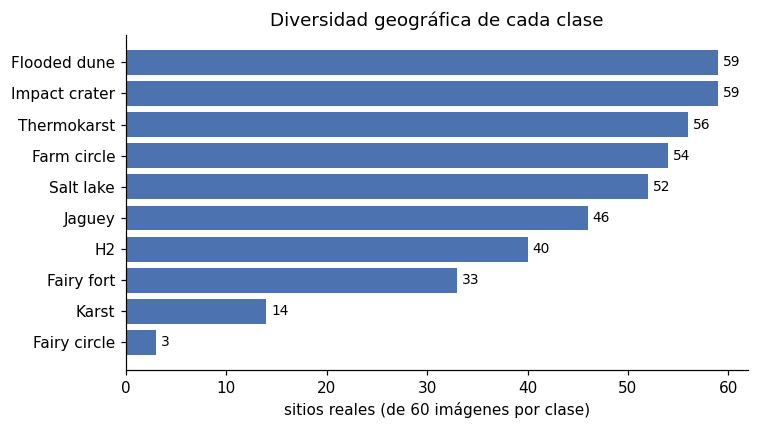

In [ ]:
df = agrupar_sitios(df)
pares = pares_solapados(df)
misma_clase = [(i, j) for i, j in pares if df.loc[i, "clase"] == df.loc[j, "clase"]]
fusionan = [(i, j) for i, j in misma_clase if df.loc[i, "cluster_id_base"] != df.loc[j, "cluster_id_base"]]
print(f"{len(pares)} pares de huellas solapadas: {len(pares) - len(misma_clase)} entre clases distintas y {len(fusionan)} que unen grupos del paso 1.")
print(f"Grupos del paso 1: {df['cluster_id_base'].nunique()}. Sitios reales tras el solape: {df['grupo_particion'].nunique()}.")

sitios = pd.DataFrame({
    "grupos (paso 1)": df.groupby("clase")["cluster_id_base"].nunique(),
    "sitios reales": df.groupby("clase")["grupo_particion"].nunique(),
    "imágenes del sitio más grande": df.groupby(["clase", "grupo_particion"]).size().groupby("clase").max(),
})
display(sitios)

fig, ax = plt.subplots(figsize=(7, 4))
orden = sitios.sort_values("sitios reales")
ax.barh(orden.index, orden["sitios reales"], color="#4C72B0")
for y_pos, n in enumerate(orden["sitios reales"]):
    ax.text(n + 0.5, y_pos, n, va="center", fontsize=9)
ax.set_xlabel("sitios reales (de 60 imágenes por clase)")
ax.set_title("Diversidad geográfica de cada clase")
fig.tight_layout()
plt.show()

Hay 35 pares de huellas solapadas, ninguno entre clases distintas, y 10 de ellos unen grupos del paso 1: los 426 grupos quedan en 416 sitios reales. Las clases tienen entre 3 y 59 sitios. Impact crater y Flooded dune son las más diversas (59 sitios para 60 fotos), y H2 y Jagüey tienen 40 y 46.

Fairy circle es el caso extremo: sus 60 fotos salen de 3 sitios, uno con 33 imágenes. Karst también es limitada, con 14 sitios y uno de 14 imágenes. Con tan pocos sitios, el reparto en pliegues no puede ser parejo para estas dos clases.

## 1.6 Holdout y pliegues

**Holdout.** Se aparta primero, antes de cualquier otra decisión, para que nada posterior lo influya: **10 imágenes por clase** formadas por sitios completos, un compromiso entre tener con qué medir cada clase y no quitarle demasiado al entrenamiento. Los sitios de cada clase se ordenan al azar con una **semilla** fija (el número que fija el azar, para que repetir el notebook dé el mismo resultado) y se toman los que caben en la cuota. Si falta cupo, se agrega el sitio completo más pequeño que quede, aunque la clase se pase de 10: es preferible a partir un sitio.

**Pliegues.** El resto se divide en 5 pliegues con `StratifiedGroupKFold`, que respeta los **grupos** (un sitio nunca queda en dos pliegues) y **estratifica** (cada pliegue conserva una proporción parecida de cada clase). Como el resultado depende del azar y con pocos sitios puede salir muy desigual, se prueban 200 semillas y se conserva la que deja menos combinaciones clase-pliegue vacías y, a igualdad, el reparto más parejo. La elección mira solo los conteos, nunca un modelo.

In [ ]:
df, pliegues = repartir(df)
print(f"Reparto elegido: semilla {pliegues['semilla']}, {pliegues['huecos']} combinaciones clase-pliegue vacías.")

reparto = pd.crosstab(df["clase"], df["split"])[["holdout", "cv"]].rename_axis(index=None, columns=None)
reparto["total"] = reparto.sum(axis=1)
display(reparto)
print(f"Holdout: {(df['split'] == 'holdout').sum()} imágenes. Validación cruzada: {(df['split'] == 'cv').sum()}.")

Reparto elegido: semilla 228, 3 combinaciones clase-pliegue vacías.


,holdout,cv,total
Fairy circle,11,49,60
Fairy fort,10,50,60
Farm circle,10,50,60
Flooded dune,10,50,60
H2,10,50,60
Impact crater,10,50,60
Jaguey,10,50,60
Karst,10,50,60
Salt lake,10,50,60
Thermokarst,10,50,60


Holdout: 101 imágenes. Validación cruzada: 499.


El holdout suma 101 imágenes: 10 por clase, salvo Fairy circle con 11. Sus 3 sitios tienen 33, 16 y 11 imágenes, y no hay forma de llegar a 10 sin partir uno, así que se lleva el de 11 completo. Por eso la validación cruzada tiene 499 imágenes y no 500.

In [ ]:
por_pliegue = pd.crosstab(df.loc[df["split"] == "cv", "clase"], df.loc[df["split"] == "cv", "fold_val"]).add_prefix("pliegue ").rename_axis(index=None, columns=None)
display(por_pliegue)

fig, ax = plt.subplots(figsize=(8, 4.5))
colores = ["#C44E52"] + [plt.get_cmap("Blues")(0.3 + 0.13 * k) for k in range(N_PLIEGUES)]
pd.concat([reparto["holdout"], por_pliegue], axis=1).plot.barh(stacked=True, ax=ax, color=colores, width=0.75)
ax.set_xlabel("imágenes"); ax.set_ylabel("")
ax.set_title("Cómo quedó repartida cada clase")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
fig.tight_layout()
plt.show()

Fairy circle solo tiene imágenes de validación en los pliegues 3 y 5 (sus dos sitios restantes), así que en los pliegues 1, 2 y 4 no se puede evaluar. Esos tres huecos son inevitables con tres sitios, y en el modelamiento esta clase se reporta aparte. Las otras nueve clases están en los cinco pliegues, aunque con un reparto desigual: Karst va de 4 a 15 imágenes por pliegue y H2, de 6 a 17.

## 1.7 Verificación

Todo lo anterior se construyó para evitar fugas. Aquí se comprueba con cálculos aparte: que cada imagen tiene un solo destino (el holdout o un pliegue), que ningún sitio real ni grupo del paso 1 aparece en dos destinos y que ningún par de huellas solapadas quedó separado. Si alguna comprobación falla, el notebook se detiene.

In [ ]:
df["destino"] = destino(df)
cv, ho = df[df["split"] == "cv"], df[df["split"] == "holdout"]
comprobaciones = {
    "cada imagen tiene un solo destino": bool(ho["fold_val"].isna().all() and cv["fold_val"].between(1, N_PLIEGUES).all()),
    "ningún sitio está en holdout y en validación cruzada": not set(ho["grupo_particion"]) & set(cv["grupo_particion"]),
    "ningún sitio está en dos pliegues": bool((cv.groupby("grupo_particion")["fold_val"].nunique() == 1).all()),
    "ningún grupo del paso 1 está partido": bool((df.groupby("cluster_id_base")["destino"].nunique() == 1).all()),
    "los pares de huellas solapadas quedaron juntos": all(df.loc[i, "destino"] == df.loc[j, "destino"] for i, j in misma_clase),
}
display(pd.Series(comprobaciones, name="se cumple").to_frame())
assert all(comprobaciones.values()), "La partición tiene una fuga; no se continúa."

,se cumple
cada imagen tiene un solo destino,True
ningún sitio está en holdout y en validación cruzada,True
ningún sitio está en dos pliegues,True
ningún grupo del paso 1 está partido,True
los pares de huellas solapadas quedaron juntos,True


Además de que los sitios no se partan, interesa qué tan cerca pueden quedar una imagen de evaluación y una de entrenamiento. Para cada clase se mide la distancia mínima entre el holdout y la validación cruzada, la distancia mínima entre pliegues distintos y cuántos pares de imágenes quedaron a menos de 1 km en destinos distintos.

In [ ]:
filas = {}
for clase, sub in df.groupby("clase"):
    D = haversine_km(sub["lat"].values, sub["lon"].values, sub["lat"].values, sub["lon"].values)
    p = sub["destino"].to_numpy()
    distinto = np.triu(p[:, None] != p[None, :], k=1)
    ho_vs_cv = np.triu((p[:, None] == "holdout") != (p[None, :] == "holdout"), k=1)
    entre_pliegues = distinto & ~ho_vs_cv
    filas[clase] = {"mínima holdout–validación (km)": D[ho_vs_cv].min(),
                    "mínima entre pliegues (km)": D[entre_pliegues].min() if entre_pliegues.any() else np.nan,
                    "pares a menos de 1 km": int((D[distinto] < 1.0).sum())}
display(pd.DataFrame(filas).T.round(2).astype({"pares a menos de 1 km": int}))

,mínima holdout–validación (km),mínima entre pliegues (km),pares a menos de 1 km
Fairy circle,0.69,0.58,154
Fairy fort,1.07,1.10,0
Farm circle,1.69,1.00,0
Flooded dune,1.77,2.50,0
H2,1.24,1.01,0
Impact crater,2.04,1.89,0
Jaguey,1.28,1.09,0
Karst,1.00,1.74,0
Salt lake,2.01,1.65,0
Thermokarst,2.06,1.29,0


En nueve de las diez clases ninguna imagen de evaluación queda a menos de 1 km de una de entrenamiento, y las distancias mínimas van de 1,0 a 2,5 km. Fairy circle es la excepción: como su radio de agrupación tuvo que ser de 0,5 km, hay 154 pares a menos de 1 km en destinos distintos, el más cercano a 0,58 km. Es una limitación de esa clase, que solo tiene 3 sitios.

## 1.8 Resultado

La partición se guarda en `salidas/particion.csv` junto con su **código**, un SHA-256 calculado a partir de qué imagen quedó en qué sitio, destino y pliegue. Cualquier cambio en un solo dato lo cambia por completo, y los notebooks siguientes lo comprueban antes de usar la partición. Como todo el azar del método usa la semilla fija, volver a ejecutar este notebook produce exactamente la misma partición y el mismo código.

El mapa muestra dónde quedó cada imagen.

Código de la partición: 8e75c9024a42a82e01ee3464a787604b7b6b5df326e5e146b5e0be5281344997


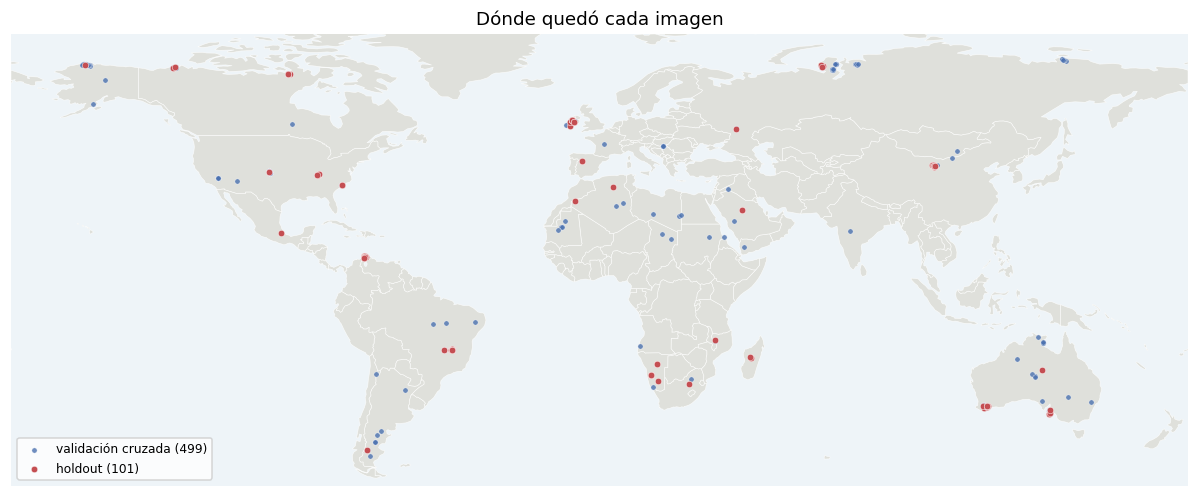

In [ ]:
OUT_DIR.mkdir(parents=True, exist_ok=True)
columnas = ["id", "clase", "carpeta", "X_3857", "Y_3857", "zoom", "ancho", "alto", "lat", "lon", "gsd_m_px",
            "huella_lado_m", "sha256", "cluster_id_base", "eps_km", "grupo_particion", "split", "fold_val"]
df[columnas].to_csv(OUT_DIR / "particion.csv", sep=";", index=False, encoding="utf-8-sig")
codigo = hash_particion(df)
(OUT_DIR / "particion.hash").write_text(codigo, encoding="utf-8")
print("Código de la partición:", codigo)

fig, ax = plt.subplots(figsize=(11, 5))
fondo_mundo(ax)
ax.scatter(cv["lon"], cv["lat"], s=12, color="#4C72B0", alpha=0.8, edgecolor="white", linewidth=0.3, label=f"validación cruzada ({len(cv)})")
ax.scatter(ho["lon"], ho["lat"], s=18, color="#C44E52", edgecolor="white", linewidth=0.3, label=f"holdout ({len(ho)})")
ax.set_title("Dónde quedó cada imagen")
ax.legend(loc="lower left", fontsize=8)
fig.tight_layout()
plt.show()

## Resumen

- 600 imágenes de 10 clases, 60 por clase, completas y sin repetidas.
- Agrupadas por cercanía sobre el globo y por solape de terreno, forman 416 sitios reales, entre 3 y 59 por clase, y ninguno quedó partido.
- Holdout: 101 imágenes (10 por clase y 11 en Fairy circle), que se evalúan una sola vez en el notebook 4.
- Validación cruzada: 499 imágenes en 5 pliegues.
- Código de la partición: `8e75c9024a42a82e01ee3464a787604b7b6b5df326e5e146b5e0be5281344997`.

Fairy circle tiene solo 3 sitios reales, un único zoom, ninguna imagen de validación en 3 de los 5 pliegues y 154 pares de imágenes a menos de 1 km en destinos distintos; sus resultados se miran aparte. El siguiente paso es `02_eda.ipynb`.